# Visualization Check

This notebook resolves one real phase-05 artifact from the canonical resolver surface, reloads and validates the persisted arrays, then renders the phase-local plotting helpers.


In [6]:
from matplotlib import pyplot as plt

from src.planner.main import load_workspace
from src.planner.phase01_candidate_generation import resolve_candidate_generation_artifacts
from src.planner.phase04_optimization import resolve_optimization_artifact
from src.planner.phase05_visualization import (
    PHASE_ARTIFACT_STEM,
    load_visualization_artifacts,
    plot_blind_spot_map,
    plot_dori_map,
    plot_metric_summary_table,
    plot_selected_configurations,
    resolve_visualization_artifact,
    save_visualization_summary,
    validate_visualization_artifacts,
)

workspace = load_workspace()
resolved_k = int(workspace.config.k_values[-1])
phase01_artifacts = resolve_candidate_generation_artifacts(
    workspace.floorplan,
    workspace.config,
    repo_root=workspace.repo_root,
)
phase04_artifacts = resolve_optimization_artifact(
    workspace.floorplan,
    workspace.config,
    repo_root=workspace.repo_root,
    k=resolved_k,
)
phase05_artifacts = resolve_visualization_artifact(
    workspace.floorplan,
    workspace.config,
    repo_root=workspace.repo_root,
    k=resolved_k,
)
phase05_artifact_path = workspace.artifact_dir / f"{PHASE_ARTIFACT_STEM}_k{resolved_k}.npz"
phase05_summary_path = workspace.artifact_dir / f"{PHASE_ARTIFACT_STEM}_k{resolved_k}_summary.json"
reloaded_phase05_artifacts = load_visualization_artifacts(phase05_artifact_path)
validate_visualization_artifacts(
    workspace.floorplan,
    phase01_artifacts,
    phase04_artifacts,
    reloaded_phase05_artifacts,
)
save_visualization_summary(phase05_summary_path, reloaded_phase05_artifacts)

{
    "phase05_artifact_path": str(phase05_artifact_path),
    "phase05_summary_path": str(phase05_summary_path),
    "resolved_k": resolved_k,
    "selected_camera_count": reloaded_phase05_artifacts.selected_camera_count,
    "open_cell_count": reloaded_phase05_artifacts.open_cell_count,
    "total_dori_score": reloaded_phase05_artifacts.metrics.total_dori_score,
    "blind_spot_pct": reloaded_phase05_artifacts.metrics.blind_spot_pct,
}


{'phase05_artifact_path': '/home/daawaan4x/repos/daawaan4x/cctv-plan/artifacts/planner/ground-back/bec358e26c32/05_metrics_k25.npz',
 'phase05_summary_path': '/home/daawaan4x/repos/daawaan4x/cctv-plan/artifacts/planner/ground-back/bec358e26c32/05_metrics_k25_summary.json',
 'resolved_k': 25,
 'selected_camera_count': 25,
 'open_cell_count': 8455,
 'total_dori_score': 26263.0,
 'blind_spot_pct': 0.8633944411590775}

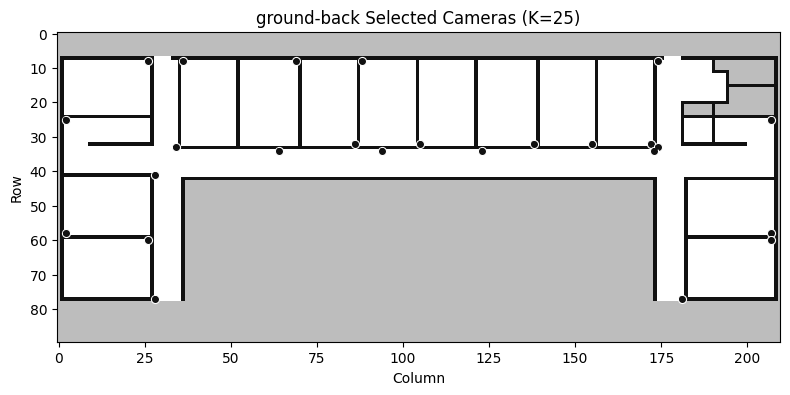

In [7]:
figure, axis = plt.subplots(figsize=(8, 6))
plot_selected_configurations(workspace.floorplan, reloaded_phase05_artifacts, ax=axis)
figure.tight_layout()
plt.show()


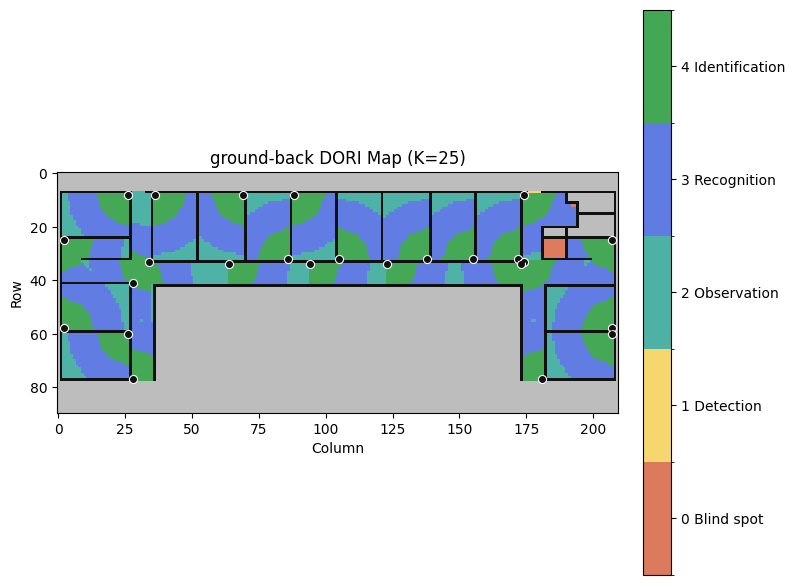

In [8]:
figure, axis = plt.subplots(figsize=(8, 6))
plot_dori_map(workspace.floorplan, reloaded_phase05_artifacts, ax=axis)
figure.tight_layout()
plt.show()


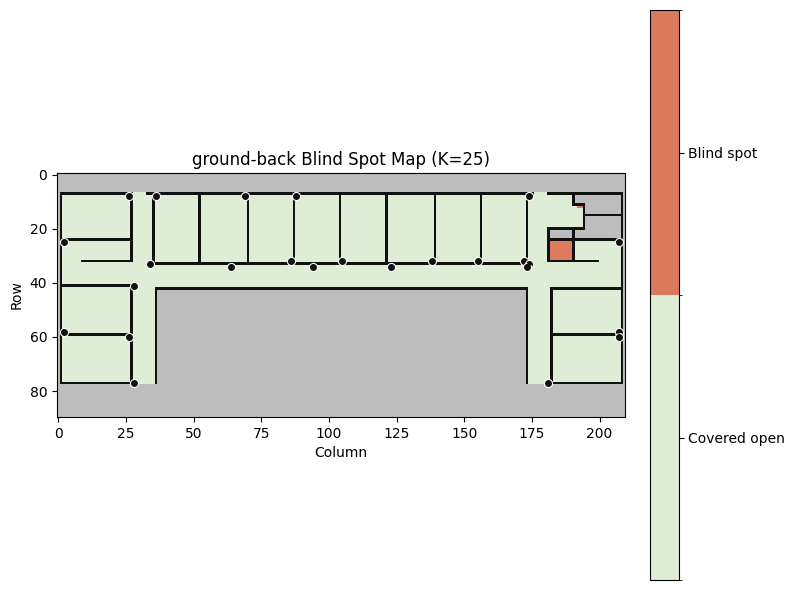

In [9]:
figure, axis = plt.subplots(figsize=(8, 6))
plot_blind_spot_map(workspace.floorplan, reloaded_phase05_artifacts, ax=axis)
figure.tight_layout()
plt.show()


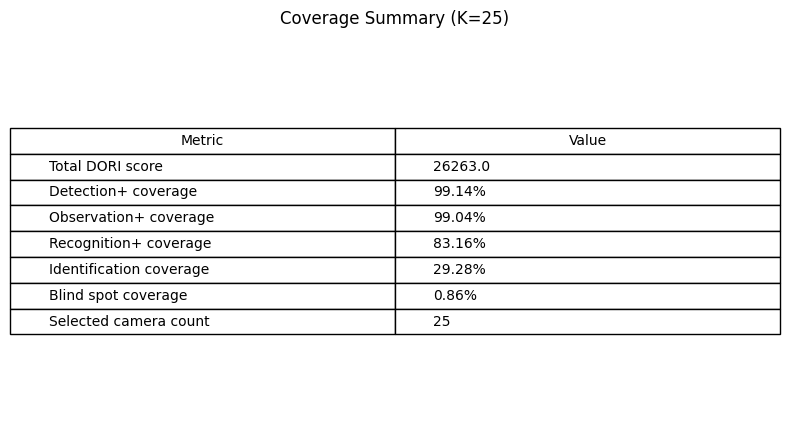

In [10]:
figure, axis = plt.subplots(figsize=(8, 4.5))
plot_metric_summary_table(reloaded_phase05_artifacts, ax=axis)
figure.tight_layout()
plt.show()
